In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as pt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler

In [37]:
#loading the data
df=pd.read_csv(r"C:\Users\PATHWAY\Downloads\SalesD.csv",parse_dates=['Date'],dayfirst=True)
df.head(25)

,Week,Date,Demand
0,1,2001-01-01,98.42
1,2,2001-01-08,122.81
2,3,2001-01-15,100.69
3,4,2001-01-22,100.54
4,5,2001-01-29,114.69
5,6,2001-02-05,105.05
6,7,2001-02-12,102.32
7,8,2001-02-19,118.37
8,9,2001-02-26,112.79
9,10,2001-03-05,115.21


In [76]:
#making Date the index
df.set_index('Date')

,Week,Demand,sma_20
Date,,,
2001-01-01,1,98.42,NaN
2001-01-08,2,122.81,NaN
2001-01-15,3,100.69,NaN
2001-01-22,4,100.54,NaN
2001-01-29,5,114.69,NaN
...,...,...,...
2026-06-01,1327,231.70,244.1075
2026-06-08,1328,236.73,243.3180
2026-06-15,1329,216.87,242.0945


In [77]:
#build the Simple moving Average Model
df['sma_20']=df['Demand'].rolling(window=20).mean()
last_sma=df['sma_20'].iloc[-1]
last_date=df['Date'].iloc[-1]

In [84]:
#forecasting the next 6-months
future_dates=pd.date_range(start=last_date,periods=25,freq='W')[1:]
forecast=pd.DataFrame({'Forecast':[last_sma]*24},index=future_dates)
print('last sma:',last_sma)


last sma: 240.402


In [85]:
forecast

,Forecast
2026-07-12,240.402
2026-07-19,240.402
2026-07-26,240.402
2026-08-02,240.402
2026-08-09,240.402
2026-08-16,240.402
2026-08-23,240.402
2026-08-30,240.402
2026-09-06,240.402
2026-09-13,240.402


In [81]:
df.head(40)

,Week,Date,Demand,sma_20
0,1,2001-01-01,98.42,NaN
1,2,2001-01-08,122.81,NaN
2,3,2001-01-15,100.69,NaN
3,4,2001-01-22,100.54,NaN
4,5,2001-01-29,114.69,NaN
5,6,2001-02-05,105.05,NaN
6,7,2001-02-12,102.32,NaN
7,8,2001-02-19,118.37,NaN
8,9,2001-02-26,112.79,NaN
9,10,2001-03-05,115.21,NaN


In [82]:
#below are performance evaluation metrics
pred=df['sma_20'].dropna().values
actual=df['Demand'].iloc[19:].values


In [83]:
mse=mean_squared_error(actual,pred)
mse

170.01544407755335

In [70]:
rmse=mse**.5
rmse

13.038997050293146

In [67]:
mae=mean_absolute_error(actual,pred)
mae

10.944278582317072

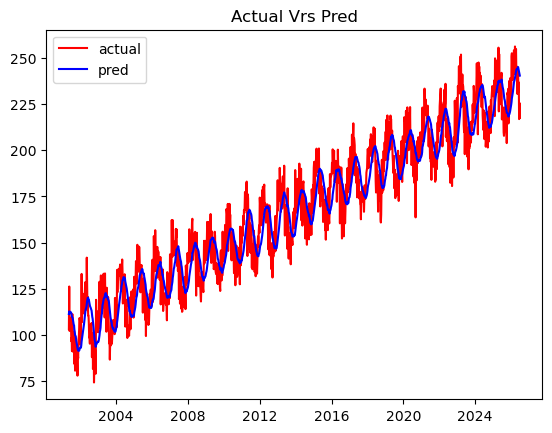

In [78]:
#compare the actual and the predicted outcome
pt.plot(df['Date'].iloc[19:],actual,color='red', label='actual')
pt.plot(df['Date'].iloc[19:],pred,color='blue',label='pred')
pt.title('Actual Vrs Pred')
pt.legend()
pt.show()